# Evidence: four data problems

Notebook for the video. It only shows evidence from the real Portal BASE data, and takes no decisions.

- The raw data section reads the header of the 2024 Excel file and one contract from the training period.
- Evidence 1 counts rows of every file published in 2025, including November and December, but looks at nothing else in that period.
- Evidence 2 and 3 use only the training period (January 2022 to September 2025).
- Evidence 4 uses the validation month (October 2025). The test file is never opened.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "cpv_data.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import cpv_data as cd
import evaluation as ev
import prepare as pr

pd.set_option("display.max_colwidth", None)

def fmt(n):
    return f"{n:,}"

def table(df, **formats):
    return df.style.format(formats)

## The raw data: one Excel file per year

Portal BASE publishes one `.xlsx` file per year on dados.gov.pt, from 2012 to 2026. Each file has one sheet, with one row per contract.

In [2]:
import openpyxl
import pyarrow.parquet as pq

ficheiros = sorted((ROOT / "data" / "raw").glob("contratos*.xlsx"))
resumo = pd.DataFrame({
    "file": [f.name for f in ficheiros],
    "size (MB)": [f.stat().st_size / 1e6 for f in ficheiros],
    # number of rows read from the Parquet copy, which keeps every row of the .xlsx
    "contracts": [pq.ParquetFile(cd.RAW_PARQUET / f"{f.stem}.parquet").metadata.num_rows for f in ficheiros],
}).set_index("file")
table(resumo, **{"size (MB)": "{:.0f}", "contracts": "{:,}"})

,size (MB),contracts
file,,
contratos2012.xlsx,16,"64,783"
contratos2013.xlsx,20,"83,217"
contratos2014.xlsx,25,"102,516"
contratos2015.xlsx,26,"107,636"
contratos2016.xlsx,27,"114,897"
contratos2017.xlsx,31,"128,583"
contratos2018.xlsx,31,"127,891"
contratos2019.xlsx,35,"145,513"
contratos2020.xlsx,41,"176,510"


What does one row look like? Below is the first contract of the 2024 file that was published before the validation month, read straight from the Excel file. Long values are cut, and ↵ marks a line break inside a cell.

In [3]:
livro = openpyxl.load_workbook(ROOT / "data" / "raw" / "contratos2024.xlsx", read_only=True)
linhas = livro.active.iter_rows(values_only=True)
colunas = list(next(linhas))
i_pub = colunas.index("dataPublicacao")
contrato = next(dict(zip(colunas, l)) for l in linhas if l[i_pub] is not None and l[i_pub] < cd.VAL_START)
livro.close()

def mostrar(v):
    if v is None:
        return ""
    if hasattr(v, "date"):
        return v.date().isoformat()
    t = str(v).replace("\n", " ↵ ")
    return t if len(t) <= 90 else t[:87] + "..."

print(f"Columns: {len(colunas)}")
exemplo = pd.DataFrame({"value": [mostrar(contrato[c]) for c in colunas]},
                       index=pd.Index(colunas, name="column"))
TEMPO = ["dataPublicacao", "dataCelebracaoContrato", "Ano"]
(exemplo.style
 .apply(lambda s: ["background-color: #dbe8f8" if c in TEMPO else "" for c in s.index], axis=0)
 .set_properties(**{"text-align": "left"}))

Columns: 39


,value
column,
idcontrato,10424375
nAnuncio,
TipoAnuncio,
idINCM,
tipoContrato,Aquisição de serviços
idprocedimento,6845383
tipoprocedimento,Ajuste Direto Regime Geral
objectoContrato,"Serviços de limpeza de bermas, valetas e manutenção de espaços públicos: manter sem veg..."
descContrato,"ADS20231124A - Serviços de limpeza de bermas, valetas, manutenção de espaços públicos e..."


Columns used to build the model's input and label:

- `objectoContrato`, `descContrato` and `DescrAcordoQuadro`: the description of what is bought, which is the model's input;
- `CPV`: the code or codes chosen, each followed by its name, one per line. This is what the model must suggest.

Three columns (highlighted) tell us *when*:

- `dataPublicacao`: the day the contract was published on the portal. The split into train, validation and test uses this date;
- `dataCelebracaoContrato`: the day the contract was signed;
- `Ano`: a year, which is the same as the year of the file.

In this contract all three agree. Evidence 1 checks whether that is always true.

## Evidence 1: the 2025 file does not hold all the contracts published in 2025

**What we assumed:** the 2025 file holds the contracts published in 2025.

**Question:** in which files are the contracts published in 2025?

In [4]:
pub_2025 = cd.load_contracts(["dataCelebracaoContrato"],
                             since=pd.Timestamp("2025-01-01"), until=pd.Timestamp("2026-01-01"))

por_ficheiro = pub_2025["ficheiro"].value_counts()
grupos = {"2014 to 2021": por_ficheiro[por_ficheiro.index <= 2021].sum()}
grupos |= {str(y): por_ficheiro.get(y, 0) for y in [2022, 2023, 2024, 2025, 2026]}
tabela = pd.DataFrame({"published in 2025": grupos}).rename_axis("file")
tabela["share"] = tabela["published in 2025"] / len(pub_2025)
table(tabela, **{"published in 2025": "{:,}", "share": "{:.1%}"})

,published in 2025,share
file,,
2014 to 2021,344,0.1%
2022,747,0.3%
2023,"2,930",1.1%
2024,"25,877",10.1%
2025,"225,106",88.3%
2026,7,0.0%


In [5]:
fora = ~pub_2025["ficheiro"].isin([2025, 2026])
print(f"Published in 2025: {fmt(len(pub_2025))}")
print(f"Outside the 2025 and 2026 files: {fmt(int(fora.sum()))} ({fora.mean():.1%})")

Published in 2025: 255,011
Outside the 2025 and 2026 files: 29,898 (11.7%)


So what does the year of a file mean? Take the contracts published in 2025 that sit in the 2024 file, and check the year they were signed.

In [6]:
no_2024 = pub_2025[pub_2025["ficheiro"] == 2024]
assinado = pd.to_datetime(no_2024["dataCelebracaoContrato"], errors="coerce").dt.year
print(f"Published in 2025, in the 2024 file: {fmt(len(no_2024))}")
print(f"   signed in 2024: {fmt(int((assinado == 2024).sum()))}")
print(f"   no valid signing date: {fmt(int(assinado.isna().sum()))}")
del pub_2025, no_2024

Published in 2025, in the 2024 file: 25,877
   signed in 2024: 25,777
   no valid signing date: 100


## Training contracts used in evidence 2 and 3

Rebuilt with the functions of `src/prepare.py`, stopping before the validation month.

In [7]:
partes = [pr.load_one(p, since=cd.TRAIN_START, until=cd.VAL_START)[0]
          for p in sorted(cd.RAW_PARQUET.glob("contratos*.parquet"))]
treino = pr.add_columns(pr.dedupe_ids(pd.concat(partes, ignore_index=True)))
del partes
treino["texto_norm"] = cd.normalize_text(treino["texto"])

cpv = cd.load_contracts(["CPV"], since=cd.TRAIN_START, until=cd.VAL_START)["CPV"]
pares = cpv.dropna().str.split("\n").explode().str.strip().str.extract(r"^(\d{8})-\d\s*-\s*(.*)$").dropna()
nome_cpv = pares.drop_duplicates(0).set_index(0)[1]
del cpv, pares

print(f"Training contracts: {fmt(len(treino))}")

Training contracts: 794,883


## Evidence 2: the same text gets different codes

The text below means "purchase of IT equipment". Division-level codes are left out here, so every code in the table is more specific than a division.

In [8]:
especificos = treino[treino["nivel"] > 2]
TEXTO = "aquisição de equipamento informático"
exemplo = especificos[especificos["texto_norm"] == TEXTO]
contagem = exemplo["codigo"].value_counts()

print(f"Text: {TEXTO}")
print(f"Contracts: {fmt(len(exemplo))}")
print(f"Buyers: {fmt(exemplo['adjudicante'].nunique())}")
print(f"Different codes: {fmt(len(contagem))}")

tabela = contagem.head(5).rename("contracts").rename_axis("code").to_frame()
tabela.insert(0, "name", tabela.index.map(nome_cpv))
tabela

Text: aquisição de equipamento informático
Contracts: 336
Buyers: 133
Different codes: 32


,name,contracts
code,,
30230000,Equipamento informático,141
30200000,Equipamento e material informático,96
30236000,Equipamento informático diverso,25
30213100,Computadores portáteis,17
30213000,Computadores pessoais,13


How common is this across all the training texts?

In [9]:
por_texto = especificos.groupby(["texto_norm", "codigo"], observed=True).size().groupby("texto_norm").agg(["sum", "size", "max"])
print(f"Texts with more than one code: {fmt(int((por_texto['size'] > 1).sum()))}")
print(f"Contracts outside the most common code of their text: {fmt(int((por_texto['sum'] - por_texto['max']).sum()))}")
del por_texto

Texts with more than one code: 6,849
Contracts outside the most common code of their text: 14,348


## Evidence 3: many contracts stop at the most generic level

The level of a code is its number of digits before the trailing zeros: `33000000` is a division, `33600000` a group. This is an approximation, not checked code by code against the official table.

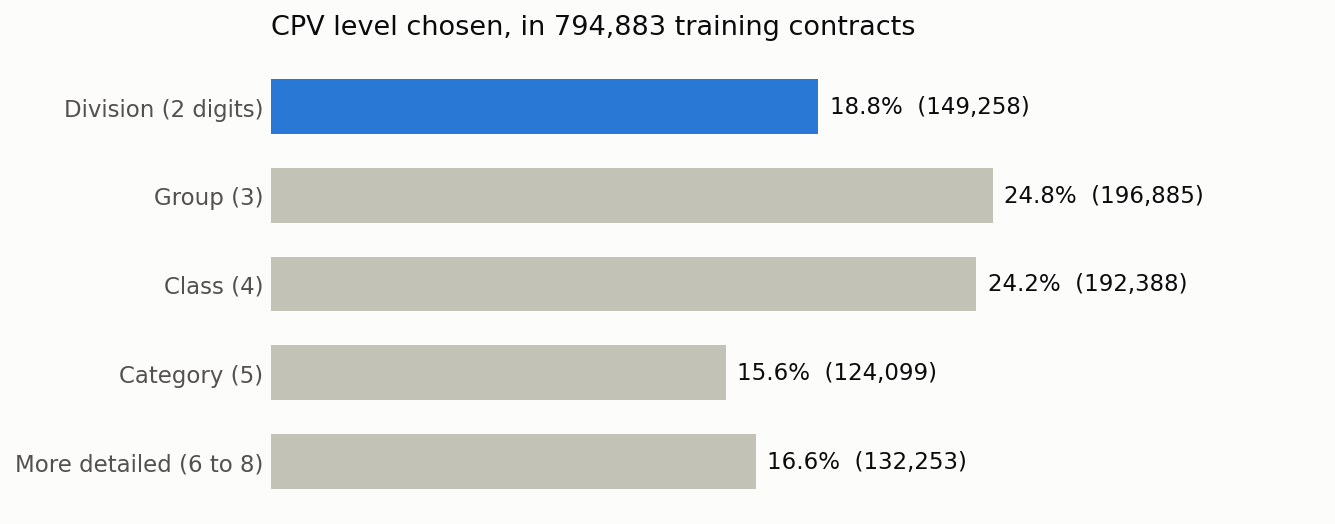

In [10]:
ORDEM = {2: "Division (2 digits)", 3: "Group (3)", 4: "Class (4)", 5: "Category (5)", 6: "More detailed (6 to 8)"}
niveis = treino["nivel"].clip(upper=6).value_counts().sort_index()
niveis.index = niveis.index.map(ORDEM)
partes_pct = niveis / niveis.sum()

DESTAQUE, CINZENTO, TEXTO_1, TEXTO_2, FUNDO = "#2a78d6", "#c3c2b7", "#0b0b0b", "#52514e", "#fcfcfb"
fig, ax = plt.subplots(figsize=(9, 3.6), dpi=150, facecolor=FUNDO)
ax.set_facecolor(FUNDO)
cores = [DESTAQUE if n == ORDEM[2] else CINZENTO for n in niveis.index]
barras = ax.barh(list(niveis.index), partes_pct * 100, color=cores, height=0.62)
ax.invert_yaxis()
for barra, n, p in zip(barras, niveis, partes_pct):
    ax.text(barra.get_width() + 0.4, barra.get_y() + barra.get_height() / 2,
            f"{p:.1%}  ({fmt(int(n))})", va="center", fontsize=11, color=TEXTO_1)
ax.set_title(f"CPV level chosen, in {fmt(int(niveis.sum()))} training contracts",
             loc="left", fontsize=13, color=TEXTO_1, pad=12)
ax.set_xlim(0, 36)
ax.xaxis.set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11, labelcolor=TEXTO_2)
for lado in ["top", "right", "bottom", "left"]:
    ax.spines[lado].set_visible(False)
fig.tight_layout()
plt.show()

Generic is not the same as wrong: a contract buying many different products can be correctly classified at a high level.

The clearest example is the exact text "medicamentos" ("medicines"):

In [11]:
medicamentos = treino[treino["texto_norm"] == "medicamentos"]
contagem = medicamentos["codigo"].value_counts()
tabela = contagem.rename("contracts").rename_axis("code").to_frame()
tabela.insert(0, "name", tabela.index.map(nome_cpv))
print(f"Contracts: {fmt(len(medicamentos))}")
tabela

Contracts: 6,100


,name,contracts
code,,
33000000,"Equipamento médico, medicamentos e produtos para cuidados pessoais",6095
33690000,Medicamentos vários,2
24000000,Produtos químicos,1
32000000,"Equipamento de rádio, televisão, comunicação, telecomunicações e afins",1
33600000,Produtos farmacêuticos,1


## Evidence 4: repeated texts make the model look better

Validation contracts from October 2025, scored with the suggestions of the TF-IDF model (`metrics/validacao.json` names the file). "Top-5" means the right full code is among the 5 suggestions.

First, how many validation contracts have a text that already appears in training?

In [12]:
validacao = pd.read_parquet(ROOT / "data" / "processed" / "validacao.parquet",
                            columns=["idcontrato", "texto", "codigos", "visto_no_treino"])
visto = validacao["visto_no_treino"]
print(f"Validation contracts: {fmt(len(validacao))}")
print(f"Text already seen in training: {fmt(int(visto.sum()))} ({visto.mean():.1%})")

(validacao.loc[visto, "texto"].str.lower().str.slice(0, 70).value_counts().head(5)
 .rename("validation contracts").rename_axis("most repeated seen texts").to_frame())

Validation contracts: 23,945
Text already seen in training: 3,706 (15.5%)


,validation contracts
most repeated seen texts,
medicamentos,259
convite à apresentação de propostas ao abrigo do(s) acordo(s)-quadro 2,237
transporte de doentes,169
aquisição de serviço de viagens e alojamento – plataforma siav | acord,89
aquisição material para bloco operatório ortopedia,79


In [13]:
FICHEIRO = ROOT / "metrics" / "e4_s1" / "n_min_10_ep_24" / "sugestoes_validacao_tau0.25.parquet"
sugestoes = pd.read_parquet(FICHEIRO)
dados = validacao.merge(sugestoes, on="idcontrato", validate="one_to_one")
sug = dados["sugestoes"].map(list)
vistos = dados["visto_no_treino"].astype(bool)

linhas = {}
for nome, mascara in [("Text already seen in training", vistos), ("New text", ~vistos),
                      ("All contracts", vistos | ~vistos)]:
    r = ev.evaluate(sug[mascara], dados.loc[mascara, "codigos"]).loc["codigo"]
    linhas[nome] = {"contracts scored": int(r["contratos"]), "top-5, full code": r["top5"]}
tabela = pd.DataFrame(linhas).T
tabela["contracts scored"] = tabela["contracts scored"].astype(int)
table(tabela, **{"contracts scored": "{:,}", "top-5, full code": "{:.2%}"})

,contracts scored,"top-5, full code"
Text already seen in training,"3,341",94.25%
New text,"16,565",75.14%
All contracts,"19,906",78.35%


The gap alone does not prove memorisation: repeated texts may also be easier. It does show that a single score mixes two very different groups of contracts.